In [2]:
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
# importing the data
df1 = pd.read_csv("Yellow Taxi Trips - Week 1.csv")
df2 = pd.read_csv("Yellow Taxi Trips - Week 2.csv")
df3 = pd.read_csv("Yellow Taxi Trips - Week 3.csv")
df4 = pd.read_csv("Yellow Taxi Trips - Week 4.csv")
df5 = pd.read_csv("Yellow Taxi Trips - Week 5.csv")

In [4]:
# concatentaing the dataframes
df = pd.concat([df1, df2, df3, df4, df5])
df.info()

<class 'pandas.DataFrame'>
Index: 2367338 entries, 0 to 177534
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   ID               int64  
 1   Pickup_Date      str    
 2   Week_No          int64  
 3   Passenger_Count  int64  
 4   Trip_Distance    float64
 5   Tip_Amount       float64
 6   Total_Amount     float64
 7   Airport_Fee      float64
 8   Payment_Type     str    
 9   Rate_Code        str    
dtypes: float64(4), int64(3), str(3)
memory usage: 198.7 MB


In [5]:
df['Pickup_Date'] = pd.to_datetime(df['Pickup_Date'], format = '%d/%m/%Y')
df.info()

<class 'pandas.DataFrame'>
Index: 2367338 entries, 0 to 177534
Data columns (total 10 columns):
 #   Column           Dtype         
---  ------           -----         
 0   ID               int64         
 1   Pickup_Date      datetime64[us]
 2   Week_No          int64         
 3   Passenger_Count  int64         
 4   Trip_Distance    float64       
 5   Tip_Amount       float64       
 6   Total_Amount     float64       
 7   Airport_Fee      float64       
 8   Payment_Type     str           
 9   Rate_Code        str           
dtypes: datetime64[us](1), float64(4), int64(3), str(2)
memory usage: 198.7 MB


In [6]:
# looking at the top rows
df.head(10)

,ID,Pickup_Date,Week_No,Passenger_Count,Trip_Distance,Tip_Amount,Total_Amount,Airport_Fee,Payment_Type,Rate_Code
0,418880,2022-01-07,1,1,17.45,0.0,79.05,0.0,Credit card,Newark
1,266865,2022-01-05,1,1,18.25,0.0,84.05,0.0,Cash,Newark
2,227117,2022-01-04,1,1,18.35,0.0,84.05,0.0,Credit card,Newark
3,193883,2022-01-04,1,1,17.70,0.0,78.05,0.0,Credit card,Newark
4,193349,2022-01-04,1,1,16.01,0.0,75.05,0.0,Cash,Newark
5,107100,2022-01-02,1,1,18.59,0.0,82.55,0.0,Cash,Newark
6,105095,2022-01-02,1,1,17.39,0.0,85.55,0.0,Cash,Newark
7,101542,2022-01-02,1,1,27.67,0.0,105.55,0.0,Cash,Newark
8,101206,2022-01-02,1,1,13.53,0.0,73.05,0.0,Cash,Newark
9,100809,2022-01-02,1,1,19.53,0.0,84.05,0.0,Cash,Newark


In [7]:
# calculating the total number of trips per day
trips = df.groupby(by = 'Pickup_Date', as_index = False )['ID'].count()
trips.head(10)

,Pickup_Date,ID
0,2022-01-01,60535
1,2022-01-02,56692
2,2022-01-03,70059
3,2022-01-04,72209
4,2022-01-05,72176
5,2022-01-06,77431
6,2022-01-07,68907
7,2022-01-08,80555
8,2022-01-09,61989
9,2022-01-10,71239


In [8]:
# renaming the ID column
trips.rename(columns = {'ID': 'Trips'}, inplace = True)
trips.head(10)

C:\Users\robfr\AppData\Local\Temp\ipykernel_33080\2438825555.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  trips.rename(columns = {'ID': 'Trips'}, inplace = True)


,Pickup_Date,Trips
0,2022-01-01,60535
1,2022-01-02,56692
2,2022-01-03,70059
3,2022-01-04,72209
4,2022-01-05,72176
5,2022-01-06,77431
6,2022-01-07,68907
7,2022-01-08,80555
8,2022-01-09,61989
9,2022-01-10,71239


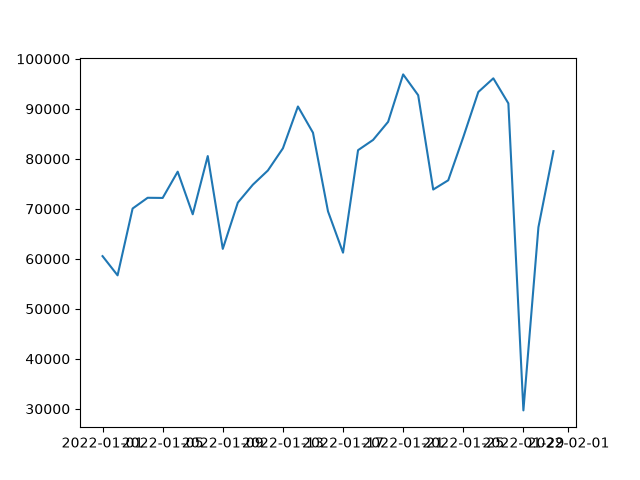

In [9]:
# creating a line chart using the scripting layer
plt.plot(trips['Pickup_Date'], trips['Trips'])

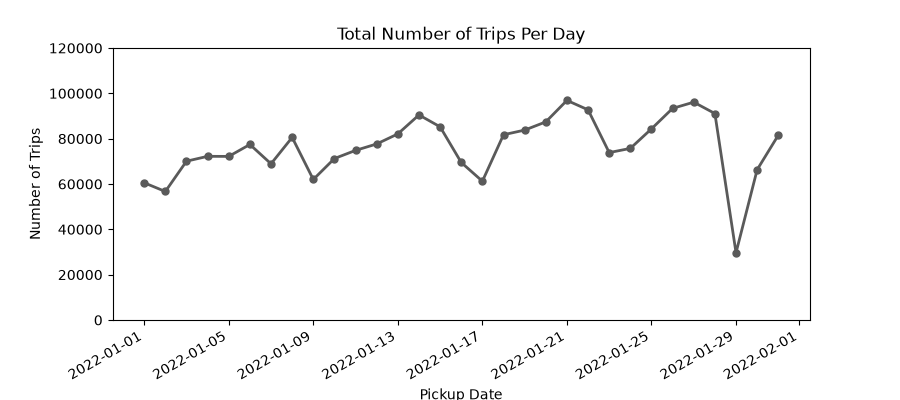

In [19]:
# creating a line chart using the object-oriented layer
fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(trips['Pickup_Date'], trips['Trips'], linestyle = '-', marker = '.', color = '#5A5A5A', markersize = 10, linewidth = 2 )
ax.set_title('Total Number of Trips Per Day')
ax.set_xlabel('Pickup Date')
ax.set_ylabel('Number of Trips')
ax.set_ylim(0, 120000)
fig.autofmt_xdate()